# 02 · Segmentación de agua con machine learning por píxel (NISAR)

Clasificación supervisada por píxel: cada píxel de la imagen NISAR se convierte en **una fila de características**, la
máscara del mismo día da su **etiqueta**, se entrena un clasificador y las predicciones se **vuelven a poner en su posición**
para reconstruir la máscara. Al final se compara con la U-Net del notebook 01.

1. Datos · 2. Preprocesamiento · 3. Normalización · 4. Modelos · 5. Resultados · 6. Aplicación externa · 7. Conclusiones

Requiere haber ejecutado `01_segmentacion_deep_learning.ipynb` (imágenes en la grilla de 5 m, máscaras, validación de los
datos y U-Net).

## 1. Datos

Las escenas de lluvia que pasaron la validación de datos del notebook 01 (sección 2.5), con su rol.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio
from scipy import ndimage

datos = pd.read_csv("Data/procesado/validacion_datos.csv")
datos = datos[datos.sirve]
datos.groupby("rol").clave.apply(list)

rol
externa                                  [tumbes_2026-10-24]
train      [lima_2026-01-14, lima_2026-08-18, lima_2026-1...
val                                        [lima_2026-10-24]
Name: clave, dtype: object

## 2. Preprocesamiento: de imagen a tabla de píxeles

Las imágenes ya están en la grilla de 5 m y en dB (notebook 01, sección 2). Cada píxel pasa a ser una fila con 6 columnas:

| Característica | Por qué |
|---|---|
| HH | el agua lisa sale oscura |
| media 3×3, 7×7 y 15×15 de HH | contexto del vecindario y menos moteado |
| desviación 7×7 y 15×15 de HH | textura: el agua es homogénea, la ciudad y los cerros no |

In [2]:
def leer(clave):
    ciudad, fecha = clave.split("_")[0], clave[-10:].replace("-", "")
    with rasterio.open(f"Data/procesado/nisar/{ciudad}/hh_{fecha}.tif") as f:
        hh, perfil = f.read(1), f.profile
    return hh, np.isfinite(hh), perfil


def suave(hh, valido, n=5):
    lineal = ndimage.uniform_filter(np.where(valido, 10 ** (hh / 10), 0), n)
    peso = ndimage.uniform_filter(valido.astype("float32"), n)
    return np.where(valido, 10 * np.log10(lineal / np.maximum(peso, 1e-6) + 1e-10), np.nan).astype("float32")


def etiqueta(clave):
    with rasterio.open(f"Data/procesado/etiquetas/{clave}.tif") as f:
        return f.read(1)


nombres = ["HH", "HH media 3x3", "HH media 7x7", "HH media 15x15", "HH desv 7x7", "HH desv 15x15"]


def caracteristicas(hh):
    x = np.clip(np.nan_to_num(hh, nan=-35), -35, 10)
    media = ndimage.uniform_filter
    desv = lambda n: np.sqrt(np.maximum(media(x * x, n) - media(x, n) ** 2, 0))
    return np.stack([x, media(x, 3), media(x, 7), media(x, 15), desv(7), desv(15)], axis=-1).reshape(-1, 6)

De cada escena de train se toman 50 000 píxeles de agua y 50 000 de tierra; de la de validación, 300 000 píxeles al azar
(con la proporción real de agua). `pixel` guarda la posición de cada fila en la imagen.

In [3]:
rng = np.random.default_rng(0)
train, val = [], []
for e in datos[datos.rol != "externa"].itertuples():
    hh, valido, perfil = leer(e.clave)
    et = etiqueta(e.clave).ravel()
    if e.rol == "train":
        idx = np.concatenate([rng.choice(np.flatnonzero(et == 1), 50_000), rng.choice(np.flatnonzero(et == 0), 50_000)])
    else:
        idx = rng.choice(np.flatnonzero(et != 255), 300_000)
    tabla = pd.DataFrame(caracteristicas(hh)[idx], columns=nombres).assign(agua=et[idx] == 1, clave=e.clave, pixel=idx)
    (train if e.rol == "train" else val).append(tabla)
train, val = pd.concat(train, ignore_index=True), pd.concat(val, ignore_index=True)
print(f"train {len(train):,} filas ({train.agua.mean():.0%} agua) · validación {len(val):,} filas ({val.agua.mean():.1%} agua)")
train.head()

train 300,000 filas (50% agua) · validación 300,000 filas (18.2% agua)


,HH,HH media 3x3,HH media 7x7,HH media 15x15,HH desv 7x7,HH desv 15x15,agua,clave,pixel
0,-16.774092,-17.332060,-20.156670,-19.760193,2.626662,2.836745,True,lima_2026-01-14,82844363
1,-14.043756,-12.888947,-16.101990,-15.959802,2.867001,2.810894,True,lima_2026-01-14,69139617
2,-15.151606,-17.193497,-16.766605,-16.716164,2.784622,3.466052,True,lima_2026-01-14,101033115
3,-18.978674,-19.448128,-21.395403,-21.021185,2.737693,3.365442,True,lima_2026-01-14,98126114
4,-13.815665,-17.586468,-20.435989,-19.600512,3.634824,3.072156,True,lima_2026-01-14,87669381


## 3. Normalización

Cada característica se estandariza (media 0, desviación 1) con un `StandardScaler` ajustado **solo con train**. Va dentro del
mismo `Pipeline` que el clasificador, así que validación, Tumbes, Arequipa o una escena nueva reciben la misma transformación.

In [4]:
from sklearn.preprocessing import StandardScaler

escala = StandardScaler().fit(train[nombres])
pd.DataFrame({"media train": escala.mean_, "desviación train": escala.scale_,
              "media val escalada": escala.transform(val[nombres]).mean(0),
              "desv. val escalada": escala.transform(val[nombres]).std(0)}, index=nombres).round(3)

,media train,desviación train,media val escalada,desv. val escalada
HH,-12.800,7.079,0.689,1.017
HH media 3x3,-12.803,6.494,0.751,1.020
HH media 7x7,-12.796,6.147,0.793,1.015
HH media 15x15,-12.776,5.911,0.821,1.002
HH desv 7x7,3.409,0.864,0.071,1.049
HH desv 15x15,3.794,0.920,0.199,1.052


## 4. Modelos

| Modelo | Idea |
|---|---|
| Regresión logística | frontera lineal entre agua y tierra |
| Random Forest | 150 árboles con muestras al azar; vota la mayoría |
| Gradient Boosting | árboles en serie; cada uno corrige el error del anterior |

El umbral de decisión de cada uno se elige maximizando el IoU en validación.

In [5]:
import joblib, time
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier


def metricas(pred, ref):
    tp, fp, fn = (pred & ref).sum(), (pred & ~ref).sum(), (~pred & ref).sum()
    return {"IoU": tp / max(tp + fp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1)}


clasificadores = {"regresion_logistica": LogisticRegression(max_iter=1000),
                  "random_forest": RandomForestClassifier(150, max_depth=16, min_samples_leaf=20, n_jobs=-1, random_state=0),
                  "gradient_boosting": HistGradientBoostingClassifier(max_iter=300, random_state=0)}
Path("Data/procesado/ml").mkdir(parents=True, exist_ok=True)
modelos, prob, umbral = {}, {}, {}
for nombre, clf in clasificadores.items():
    inicio = time.time()
    modelos[nombre] = make_pipeline(StandardScaler(), clf).fit(train[nombres], train.agua)
    prob[nombre] = modelos[nombre].predict_proba(val[nombres])[:, 1]
    umbral[nombre] = max(np.arange(0.1, 0.95, 0.05).round(2), key=lambda u: metricas(prob[nombre] >= u, val.agua.to_numpy())["IoU"])
    joblib.dump({"modelo": modelos[nombre], "umbral": umbral[nombre], "caracteristicas": nombres}, f"Data/procesado/ml/{nombre}.joblib")
    print(f"{nombre}: {time.time() - inicio:.0f} s · umbral {umbral[nombre]}")

regresion_logistica: 0 s · umbral 0.55


random_forest: 11 s · umbral 0.5


gradient_boosting: 1 s · umbral 0.5


## 5. Resultados en validación

Todos los modelos se miden sobre **los mismos píxeles de validación**. La U-Net del notebook 01 se aplica a la misma escena
y se leen sus probabilidades en esos mismos píxeles. Como en el notebook 01, luego se separa el acierto entre el agua
permanente de WorldCover (sobre todo el mar) y la tierra a más de 200 m de ella, donde estaría el agua empozada.

In [6]:
import torch, segmentation_models_pytorch as smp

gpu = "cuda" if torch.cuda.is_available() else "cpu"
encoder = pd.read_csv("Data/procesado/dl/resultados_validacion.csv").encoder[0]
guardado = torch.load(f"Data/procesado/dl/unet_{encoder}.pt")
unet = smp.Unet(encoder, encoder_weights=None, in_channels=1, classes=1).to(gpu)
unet.load_state_dict(guardado["pesos"])
media, desv = np.array(guardado["media"], "float32"), np.array(guardado["desv"], "float32")


def normalizar(x):
    return np.nan_to_num((np.clip(x.astype("float32"), -35, 10) - media[:, None, None]) / desv[:, None, None])


def mapa(modelo, hh):
    modelo.eval()
    x = normalizar(hh[None])
    alto, ancho = hh.shape
    suma, veces = np.zeros((alto, ancho), "float32"), np.zeros((alto, ancho), "float32")
    filas = list(range(0, alto - 256, 128)) + [alto - 256]
    columnas = list(range(0, ancho - 256, 128)) + [ancho - 256]
    with torch.no_grad(), torch.autocast(gpu, dtype=torch.bfloat16):
        for i in filas:
            lote = torch.tensor(np.stack([x[:, i:i + 256, j:j + 256] for j in columnas]), dtype=torch.float32, device=gpu)
            prob = torch.sigmoid(modelo(lote)).float().cpu().numpy()[:, 0]
            for j, pj in zip(columnas, prob):
                suma[i:i + 256, j:j + 256] += pj
                veces[i:i + 256, j:j + 256] += 1
    return suma / veces


nombre_unet = f"unet_{encoder}"
prob[nombre_unet] = np.concatenate([mapa(unet, suave(*leer(c)[:2])).ravel()[g.pixel.to_numpy()] for c, g in val.groupby("clave", sort=False)])
umbral[nombre_unet] = guardado["umbral"]
comparacion = pd.DataFrame([{"modelo": n, "familia": "U-Net" if n.startswith("unet") else "ML por píxel", "umbral": umbral[n],
                             **metricas(p >= umbral[n], val.agua.to_numpy())} for n, p in prob.items()])
comparacion = comparacion.sort_values("IoU", ascending=False)
comparacion.to_csv("Data/procesado/ml/comparacion_validacion.csv", index=False)
mejor = comparacion[comparacion.familia == "ML por píxel"].modelo.iloc[0]
print("mejor modelo por píxel:", mejor)
comparacion.round(3)

mejor modelo por píxel: random_forest


,modelo,familia,umbral,IoU,F1,Precision,Recall
1,random_forest,ML por píxel,0.50,0.786,0.880,0.843,0.921
2,gradient_boosting,ML por píxel,0.50,0.785,0.880,0.839,0.924
0,regresion_logistica,ML por píxel,0.55,0.766,0.867,0.829,0.909
3,unet_resnet34,U-Net,0.40,0.760,0.863,0.827,0.903


In [7]:
val["zona"] = "orilla (≤ 200 m)"
for c, g in val.groupby("clave"):
    with rasterio.open(f"Data/procesado/nisar/{c.split('_')[0]}/worldcover.tif") as f:
        wc = f.read(1) == 80
    lejos = ndimage.maximum_filter(wc.astype("uint8"), 81) == 0
    val.loc[g.index[wc.ravel()[g.pixel.to_numpy()]], "zona"] = "agua permanente"
    val.loc[g.index[lejos.ravel()[g.pixel.to_numpy()]], "zona"] = "tierra a más de 200 m"
del wc, lejos
filas = []
for z, g in val[val.zona != "orilla (≤ 200 m)"].groupby("zona"):
    for n, p in prob.items():
        q = p[g.index] >= umbral[n]
        filas.append({"zona": z, "modelo": n, "pixeles": len(g), "agua_etiqueta_%": 100 * g.agua.mean(),
                      "agua_predicha_%": 100 * q.mean(), **metricas(q, g.agua.to_numpy())})
por_zona = pd.DataFrame(filas)
por_zona.to_csv("Data/procesado/ml/comparacion_por_zona.csv", index=False)
por_zona.round(3)

,zona,modelo,pixeles,agua_etiqueta_%,agua_predicha_%,IoU,F1,Precision,Recall
0,agua permanente,regresion_logistica,68044,74.555,72.691,0.896,0.945,0.957,0.933
1,agua permanente,random_forest,68044,74.555,72.061,0.926,0.962,0.978,0.946
2,agua permanente,gradient_boosting,68044,74.555,72.494,0.928,0.963,0.976,0.949
3,agua permanente,unet_resnet34,68044,74.555,87.100,0.807,0.893,0.829,0.968
4,tierra a más de 200 m,regresion_logistica,219376,1.420,4.417,0.164,0.281,0.186,0.578
5,tierra a más de 200 m,random_forest,219376,1.420,4.530,0.161,0.277,0.182,0.581
6,tierra a más de 200 m,gradient_boosting,219376,1.420,4.619,0.159,0.275,0.180,0.585
7,tierra a más de 200 m,unet_resnet34,219376,1.420,0.088,0.021,0.042,0.359,0.022


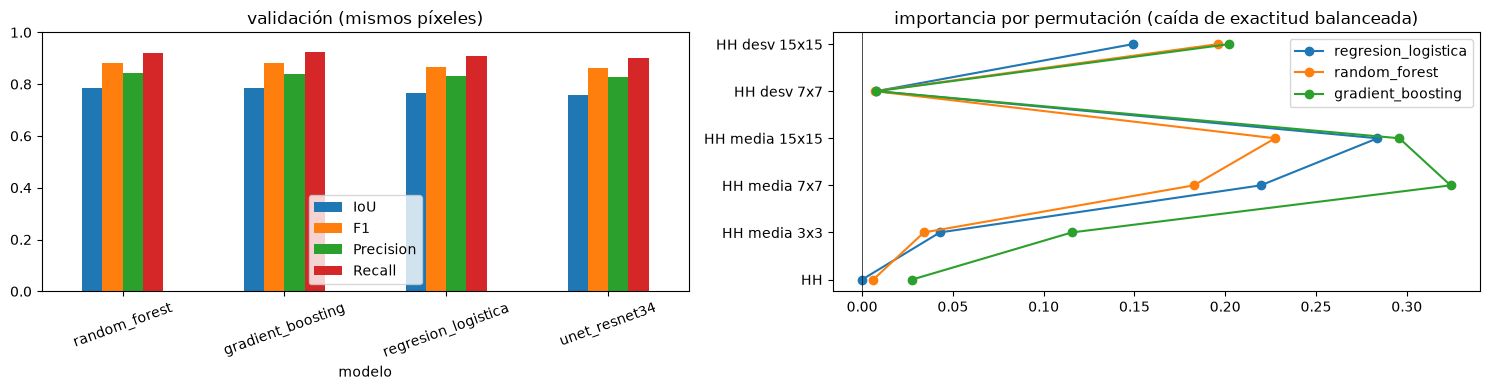

In [8]:
from sklearn.inspection import permutation_importance

fig, ejes = plt.subplots(1, 2, figsize=(15, 4))
comparacion.set_index("modelo")[["IoU", "F1", "Precision", "Recall"]].plot.bar(ax=ejes[0], rot=20, ylim=(0, 1))
ejes[0].set_title("validación (mismos píxeles)")
muestra = val.sample(20_000, random_state=0)
for nombre, m in modelos.items():
    imp = permutation_importance(m, muestra[nombres], muestra.agua, scoring="balanced_accuracy", n_repeats=3, random_state=0)
    ejes[1].plot(imp.importances_mean, nombres, "o-", label=nombre)
ejes[1].axvline(0, color="k", lw=0.5)
ejes[1].set_title("importancia por permutación (caída de exactitud balanceada)")
ejes[1].legend()
plt.tight_layout()

### 5.1 De píxeles a filas y de vuelta a la máscara

Una ventana de 12 × 12 píxeles de validación con agua y tierra: cada píxel es una fila de la tabla, el modelo da una
probabilidad por fila y con la posición de cada fila se reconstruye la máscara.

,HH,HH media 3x3,HH media 7x7,HH media 15x15,HH desv 7x7,HH desv 15x15,etiqueta,probabilidad
0,-4.68,-5.86,-8.48,-9.37,3.89,4.05,0,0.0
1,-4.52,-4.90,-7.88,-9.61,3.72,4.32,0,0.0
2,-6.15,-5.39,-7.20,-10.00,3.16,4.64,0,0.0
3,-9.93,-6.69,-7.29,-10.44,3.40,4.95,0,0.0
4,-10.81,-8.37,-7.91,-10.84,3.90,5.15,0,0.0


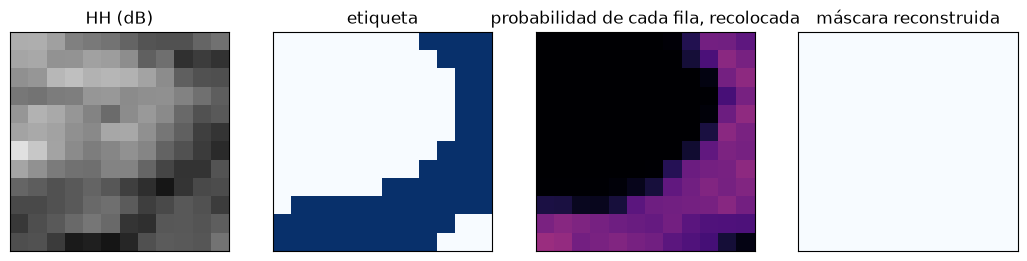

In [9]:
clave = val.clave.iloc[0]
hh, valido, perfil = leer(clave)
et = etiqueta(clave)
fraccion = ndimage.uniform_filter((et == 1).astype("float32"), 12)
completa = ndimage.uniform_filter((et != 255).astype("float32"), 12) == 1
completa[:40], completa[-40:], completa[:, :40], completa[:, -40:] = False, False, False, False
i, j = np.unravel_index(np.argmin(np.where(completa, abs(fraccion - 0.4), 9)), et.shape)
i, j = i - 6, j - 6
filas = caracteristicas(hh[i - 20:i + 32, j - 20:j + 32]).reshape(52, 52, 6)[20:32, 20:32].reshape(-1, 6)
p = modelos[mejor].predict_proba(pd.DataFrame(filas, columns=nombres))[:, 1]
display(pd.DataFrame(filas[:5], columns=nombres).assign(etiqueta=et[i:i + 12, j:j + 12].ravel()[:5], probabilidad=p[:5]).round(2))
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.4))
ejes[0].imshow(hh[i:i + 12, j:j + 12], cmap="gray", vmin=-25, vmax=5)
ejes[0].set_title("HH (dB)")
ejes[1].imshow(et[i:i + 12, j:j + 12] == 1, cmap="Blues")
ejes[1].set_title("etiqueta")
ejes[2].imshow(p.reshape(12, 12), cmap="magma", vmin=0, vmax=1)
ejes[2].set_title("probabilidad de cada fila, recolocada")
ejes[3].imshow(p.reshape(12, 12) >= umbral[mejor], cmap="Blues")
ejes[3].set_title("máscara reconstruida")
for ax in ejes:
    ax.set_xticks([])
    ax.set_yticks([])

## 6. Aplicación externa: Tumbes y Arequipa

El mejor modelo por píxel se aplica a cada escena externa que sirve (por trozos de 5 millones de píxeles), se compara con la
máscara del mismo día y con la U-Net, en toda la escena y en la tierra a más de 200 m del agua permanente, y se guarda la
probabilidad como GeoTIFF en `Data/procesado/ml/predicciones/`.

In [10]:
Path("Data/procesado/ml/predicciones").mkdir(exist_ok=True)
filas = []
for e in datos[datos.rol == "externa"].itertuples():
    hh, valido, perfil = leer(e.clave)
    tabla = caracteristicas(hh)
    p = np.full(hh.size, np.nan, "float32")
    ok = np.flatnonzero(valido.ravel())
    for k in range(0, len(ok), 5_000_000):
        trozo = ok[k:k + 5_000_000]
        p[trozo] = modelos[mejor].predict_proba(pd.DataFrame(tabla[trozo], columns=nombres))[:, 1]
    p = p.reshape(hh.shape)
    et = etiqueta(e.clave)
    with rasterio.open(f"Data/procesado/dl/predicciones/{e.clave}.tif") as f:
        p_unet = f.read(1) / 100
    with rasterio.open(f"Data/procesado/nisar/{e.ciudad}/worldcover.tif") as f:
        lejos = ndimage.maximum_filter((f.read(1) == 80).astype("uint8"), 81) == 0
    for zona, m in [("todo", et != 255), ("tierra a más de 200 m", (et != 255) & lejos)]:
        for modelo, q in [(mejor, p >= umbral[mejor]), (nombre_unet, p_unet >= umbral[nombre_unet])]:
            filas.append({"clave": e.clave, "zona": zona, "modelo": modelo, "agua_mascara_km2": (et[m] == 1).sum() * 25 / 1e6,
                          "agua_predicha_km2": q[m].sum() * 25 / 1e6, **metricas(q[m], et[m] == 1)})
    perfil.update(dtype="uint8", nodata=255, predictor=1)
    with rasterio.open(f"Data/procesado/ml/predicciones/{e.clave}.tif", "w", **perfil) as f:
        f.write(np.where(valido, np.round(np.nan_to_num(p) * 100), 255).astype("uint8"), 1)
    del tabla
externa = pd.DataFrame(filas)
externa.to_csv("Data/procesado/ml/resultados_externa.csv", index=False)
externa.round(3)

,clave,zona,modelo,agua_mascara_km2,agua_predicha_km2,IoU,F1,Precision,Recall
0,tumbes_2026-10-24,todo,random_forest,117.985,113.239,0.795,0.886,0.904,0.868
1,tumbes_2026-10-24,todo,unet_resnet34,117.985,135.523,0.811,0.896,0.838,0.962
2,tumbes_2026-10-24,tierra a más de 200 m,random_forest,7.647,11.599,0.299,0.460,0.382,0.579
3,tumbes_2026-10-24,tierra a más de 200 m,unet_resnet34,7.647,15.190,0.319,0.484,0.364,0.722


### 6.1 Tiempo de inferencia

Mismo recorte de 1024 × 1024 píxeles (26 km²): en ML incluye calcular las 6 características; en la U-Net, el promedio 5 × 5
y la ventana deslizante. Mediana de 3 repeticiones.

In [11]:
hh = leer(datos.clave.iloc[0])[0][1000:2024, 1000:2024]


def cronometrar(f):
    f()
    tiempos = []
    for _ in range(3):
        inicio = time.perf_counter()
        f()
        tiempos.append(time.perf_counter() - inicio)
    return np.median(tiempos)


tiempos = {n: cronometrar(lambda: m.predict_proba(pd.DataFrame(caracteristicas(hh), columns=nombres))) for n, m in modelos.items()}
tiempos[nombre_unet] = cronometrar(lambda: mapa(unet, suave(hh, np.isfinite(hh))))
pd.Series(tiempos, name="segundos").round(3)

regresion_logistica    0.146
random_forest          0.927
gradient_boosting      0.572
unet_resnet34          0.169
Name: segundos, dtype: float64

## 7. Conclusiones

1. **Tabla de píxeles.** 300 000 filas de train (50 % agua, Lima pista 083) y 300 000 de validación (Lima 24 oct, 18.2 %
   agua), con 6 características calculadas solo de HH.
2. **Validación.** En los mismos píxeles, los tres modelos por píxel quedan un poco por encima de la U-Net: Random Forest
   IoU 0.786, Gradient Boosting 0.785, regresión logística 0.766 y U-Net (ResNet34) 0.760. La diferencia es pequeña.
3. **Qué usa el modelo.** Lo que más pesa son los promedios del vecindario (7 × 7 y 15 × 15) y la textura 15 × 15; el HH
   del píxel solo casi no aporta, porque el moteado lo vuelve ruidoso. Igual que la U-Net, decide por el contexto.
4. **Por zona.** En el agua permanente los modelos por píxel son más precisos que la U-Net (IoU 0.90-0.93 contra 0.81: la
   U-Net marca como agua el 87 % de esa zona y la etiqueta, el 75 %). En la tierra a más de 200 m del agua permanente, los
   modelos por píxel marcan como agua el 4.4-4.6 % de la tierra (la etiqueta, el 1.4 %) y aciertan poco (IoU 0.16,
   precisión 0.18); la U-Net casi no marca nada (IoU 0.02). Ninguno separa el agua en tierra.
5. **Tumbes.** En una ciudad que no vio, Random Forest logra IoU 0.795 contra 0.811 de la U-Net; en la tierra, 0.30 contra
   0.32. La U-Net generaliza un poco mejor; Random Forest es más conservador (precisión 0.90 y recall 0.87, contra 0.84 y
   0.96).
6. **Costo.** Random Forest entrena en 11 s en CPU; cada U-Net, unos minutos en GPU. Para predecir 1024 × 1024 píxeles, la
   U-Net tarda 0.17 s en GPU; en CPU, la regresión logística tarda 0.15 s, Gradient Boosting 0.57 s y Random Forest 0.93 s,
   contando el cálculo de las características.
7. **En resumen.** Para el agua abierta grande, un clasificador por píxel con promedios del vecindario iguala a la U-Net con
   mucho menos costo de entrenamiento. Ninguno de los dos detecta el agua de lluvia en la ciudad: el límite está en la
   etiqueta y en la señal de una sola polarización, no en el modelo (ver las conclusiones del notebook 01).